# 02: Why do we lose rounds?

**Question (mine):** *is there a recurring thing that happens a lot when we lose a round? Dying early, rushing mid, etc.*

Data: 64 FACEIT demos (9 Sep to 8 Nov 2026) that match FACEIT's own scoreboard exactly, which is **1,416 rounds**.
Built with `src/parse_demos.py` and then `src/features.py`.

**One rule for this notebook:** in a lost round everyone on your team dies eventually, so "we died more" is a *result* of losing, not a cause.
I only use things that are known **before the round is decided**: the buy, the opening duel, utility thrown before first contact, and where the team stands at 0:15.

> 📝 = my own take.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())  # project root
sys.path.insert(0, str(ROOT / "src" / "pipeline"))
from features import death_context

P = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

quality = pd.read_parquet(P / "demo_quality.parquet")
OK = set(quality.loc[quality["ok"], "match_id"])

rf = pd.read_parquet(P / "round_features.parquet")          # already filtered to good demos
kills = pd.read_parquet(P / "kills.parquet").query("match_id in @OK")
grenades = pd.read_parquet(P / "grenades.parquet").query("match_id in @OK")
pr = pd.read_parquet(P / "player_rounds.parquet").query("match_id in @OK")
pos = pd.read_parquet(P / "positions.parquet").query("match_id in @OK")

gun = rf[~rf["is_pistol"]].copy()   # pistol rounds are their own thing
MAPS = {m: m.replace("de_", "").title() for m in rf["map"].unique()}

plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
WIN, LOSS, NEUTRAL, US, THEM = "#2a9d8f", "#e76f51", "#6c757d", "#264653", "#e9c46a"

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def wilson(wins, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = wins / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

print(f"{rf['match_id'].nunique()} matches, {len(rf)} rounds ({len(gun)} gun rounds), "
      f"round win rate {rf['my_team_won'].mean():.1%}")

64 matches, 1416 rounds (1288 gun rounds), round win rate 51.3%


## 1. Baseline: money

In [2]:
buy = (gun.pivot_table(index="my_team_buy", columns="enemy_buy", values="my_team_won", aggfunc=["mean", "size"])
          .reindex(["eco", "force", "full"]))
buy.round(2)

mean              size              
enemy_buy     eco force  full   eco  force   full
my_team_buy                                      
eco           NaN  0.15  0.22   NaN   39.0   54.0
force        0.87  0.50  0.37  47.0   32.0  285.0
full         0.87  0.65  0.53  54.0  222.0  555.0

Economy matters, but it's not the whole story: full buy vs full buy is a coin flip (~53%).
Something else decides those rounds. The rest of this notebook looks for it.

Side note: my team is on a weaker buy than the enemy fairly often (`force` vs `full` = 285 rounds). Something to look at another day.

## 2. The opening duel

In [3]:
gun["opening"] = np.where(gun["opening_ours"], "we got the first kill", "they got the first kill")
tab = gun.groupby(["my_side", "opening"]).agg(rounds=("round", "size"), win_rate=("my_team_won", "mean"))
tab["share_of_rounds"] = tab["rounds"] / tab.groupby(level=0)["rounds"].transform("sum")
tab.round(2)

rounds  win_rate  share_of_rounds
my_side opening                                                   
CT      they got the first kill     296      0.29             0.46
        we got the first kill       353      0.74             0.54
T       they got the first kill     322      0.31             0.50
        we got the first kill       317      0.68             0.50

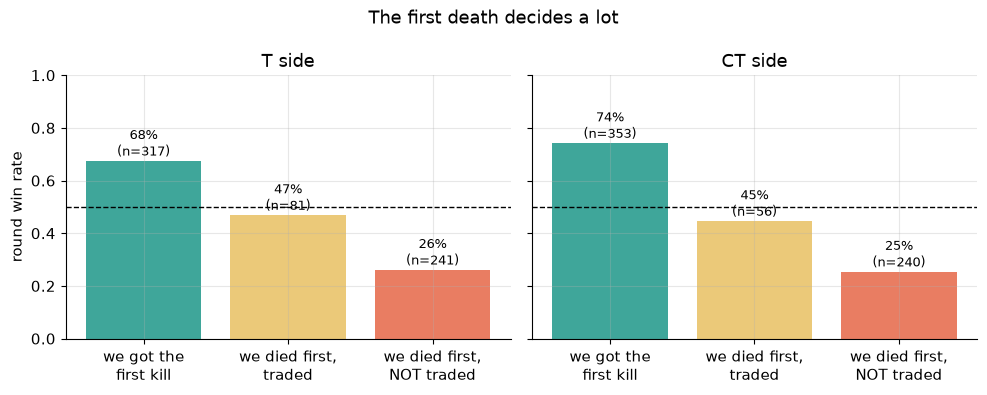

In [4]:
# when WE die first: does getting that death traded save the round?
ours = gun[~gun["opening_ours"]].copy()
ours["first death"] = np.where(ours["opening_traded"], "traded", "not traded")
t = ours.groupby(["my_side", "first death"])["my_team_won"].agg(rounds="size", wins="sum")
t["win_rate"] = t["wins"] / t["rounds"]
t[["lo", "hi"]] = [wilson(w, n) for w, n in zip(t["wins"], t["rounds"])]

theirs = gun[gun["opening_ours"]].groupby("my_side")["my_team_won"].agg(rounds="size", wins="sum")
theirs["win_rate"] = theirs["wins"] / theirs["rounds"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, side in zip(axes, ["T", "CT"]):
    labels = ["we got the\nfirst kill", "we died first,\ntraded", "we died first,\nNOT traded"]
    vals = [theirs.loc[side, "win_rate"], t.loc[(side, "traded"), "win_rate"], t.loc[(side, "not traded"), "win_rate"]]
    ns = [theirs.loc[side, "rounds"], t.loc[(side, "traded"), "rounds"], t.loc[(side, "not traded"), "rounds"]]
    bars = ax.bar(labels, vals, color=[WIN, THEM, LOSS], alpha=0.9)
    for b, v, n in zip(bars, vals, ns):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}\n(n={n})", ha="center", fontsize=9)
    ax.set_ylim(0, 1)
    ax.axhline(0.5, color="black", ls="--", lw=1)
    ax.set_title(f"{side} side")
axes[0].set_ylabel("round win rate")
fig.suptitle("The first death decides a lot")
save("02_opening_duel")

**This is the recurring thing.** If we lose the opening duel and nobody trades it, we win about **1 in 4** rounds on either side,
and that happens in roughly **37% of gun rounds**. Getting that first death traded nearly doubles our chances.

> 📝 **My take:** (react)

## 3. What actually predicts a round win? (a simple model)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

m = gun[gun["spread_15s"].notna()].copy()
m["is_T"] = (m["my_side"] == "T").astype(int)
m["equip_diff_k"] = m["equip_diff"] / 1000
m["opening_ours"] = m["opening_ours"].astype(int)
m["our_first_death_traded"] = ((m["opening_ours"] == 0) & m["opening_traded"]).astype(int)
y = m["my_team_won"].astype(int)

feature_sets = {
    "money + side": ["equip_diff_k", "is_T"],
    "+ before first contact (utility, team shape at 0:15)":
        ["equip_diff_k", "is_T", "my_util_before_contact", "enemy_util_before_contact", "max_stack_15s", "places_15s"],
    "+ opening duel":
        ["equip_diff_k", "is_T", "my_util_before_contact", "enemy_util_before_contact", "max_stack_15s", "places_15s",
         "opening_ours", "our_first_death_traded", "opening_time_s"],
}
rows = []
for name, cols in feature_sets.items():
    X = m[cols].fillna(m[cols].median())
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    # GroupKFold by match: never train and test on rounds from the same game
    auc = cross_val_score(model, X, y, cv=GroupKFold(5), groups=m["match_id"], scoring="roc_auc")
    rows.append({"features": name, "CV AUC": auc.mean().round(3), "±": auc.std().round(3)})
pd.DataFrame(rows)

,features,CV AUC,±
0,money + side,0.681,0.023
1,"+ before first contact (utility, team shape at...",0.708,0.020
2,+ opening duel,0.782,0.014


,odds,lo,hi
+1 of THEIR nades before first contact,0.93,0.88,0.99
+1 s until first kill,0.99,0.97,1.01
+$1k more equipment than them,1.05,1.04,1.07
+1 of our nades before first contact,1.06,0.99,1.13
we're T (vs CT),1.15,0.88,1.54
+1 different spot covered at 0:15,1.37,1.09,1.75
+1 player in our biggest group at 0:15,1.47,1.15,1.84
we die first but it's traded,2.71,1.72,4.22
we get the first kill,5.92,4.39,8.12


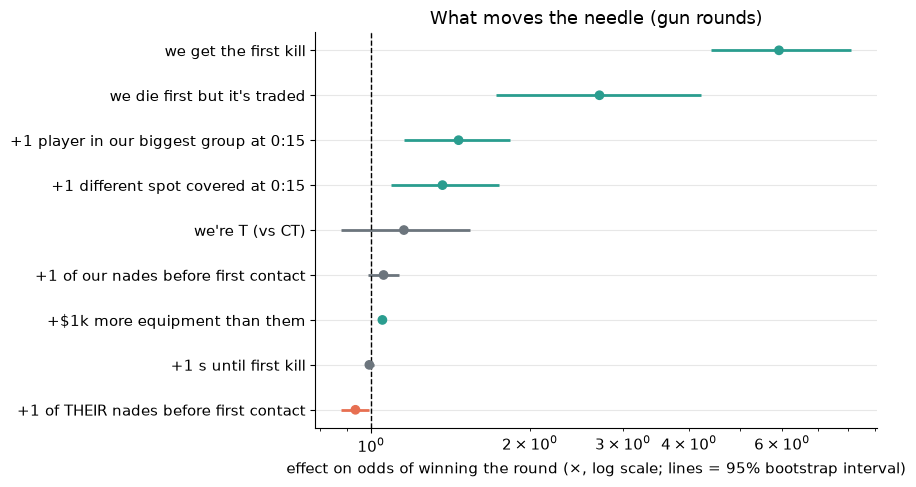

In [6]:
cols = feature_sets["+ opening duel"]
X = m[cols].fillna(m[cols].median())
nice = {
    "equip_diff_k": "+$1k more equipment than them", "is_T": "we're T (vs CT)",
    "my_util_before_contact": "+1 of our nades before first contact",
    "enemy_util_before_contact": "+1 of THEIR nades before first contact",
    "max_stack_15s": "+1 player in our biggest group at 0:15",
    "places_15s": "+1 different spot covered at 0:15",
    "opening_ours": "we get the first kill",
    "our_first_death_traded": "we die first but it's traded",
    "opening_time_s": "+1 s until first kill",
}
rng = np.random.default_rng(0)
boot = []
for _ in range(300):
    idx = rng.integers(0, len(X), len(X))
    boot.append(LogisticRegression(max_iter=2000, C=1e6).fit(X.iloc[idx], y.iloc[idx]).coef_[0])
boot = np.array(boot)
fit = LogisticRegression(max_iter=2000, C=1e6).fit(X, y)
odds = pd.DataFrame({"odds": np.exp(fit.coef_[0]), "lo": np.exp(np.percentile(boot, 2.5, 0)),
                     "hi": np.exp(np.percentile(boot, 97.5, 0))}, index=[nice[c] for c in cols]).sort_values("odds")

fig, ax = plt.subplots(figsize=(9, 5))
colors = [WIN if lo > 1 else LOSS if hi < 1 else NEUTRAL for lo, hi in zip(odds["lo"], odds["hi"])]
ax.scatter(odds["odds"], odds.index, color=colors, zorder=3)
ax.hlines(odds.index, odds["lo"], odds["hi"], color=colors, lw=2)
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("effect on odds of winning the round (×, log scale; lines = 95% bootstrap interval)")
ax.set_title("What moves the needle (gun rounds)")
save("02_round_model")
odds.round(2)

- Money + side alone gets an AUC of ~0.68. Adding what happens **before anyone dies** helps a little (~0.71).
  Adding the **opening duel** jumps it to ~0.78, which makes it the biggest single lever by far (about **6× the odds**).
- A traded first death is worth about **2.7×** the odds of an untraded one.
- Every enemy nade thrown before first contact chips away at our odds (~7% each). They prepare, we don't (see section 6).
- Spreading out *and* not leaving people alone (more spots covered, bigger groups) both help a bit.

This is correlation, not proof. But it points at the same place every time: **the first fight of the round.**

## 4. "My team is disjointed": is that true?

The fair test is to compare us against the **same kind of situations for our opponents**.
For every death I measured the distance to the nearest living teammate (≥800 units = "died alone") and whether it got traded.

In [7]:
live = kills[~kills["after_round_end"] & ~kills["is_world"]].merge(
    gun[["match_id", "round"]], on=["match_id", "round"])
ctx = death_context(live, pos)
ctx["who"] = np.where(ctx["victim_is_my_team"], "us", "opponents")
ctx["death"] = np.where(ctx["is_opening"], "opening death", "any death")
both = pd.concat([ctx.assign(death="any death"), ctx[ctx["is_opening"]].assign(death="opening death")])
comp = both.groupby(["death", "victim_side", "who"]).agg(
    deaths=("tick", "size"), died_alone=("isolated", "mean"), traded=("traded", "mean")).round(3)
comp

deaths  died_alone  traded
death         victim_side who                                  
any death     CT          opponents    2282       0.570   0.158
                          us           2196       0.541   0.173
              T           opponents    2468       0.425   0.186
                          us           2377       0.363   0.227
opening death CT          opponents     315       0.321   0.162
                          us            296       0.324   0.189
              T           opponents     349       0.203   0.226
                          us            321       0.234   0.252

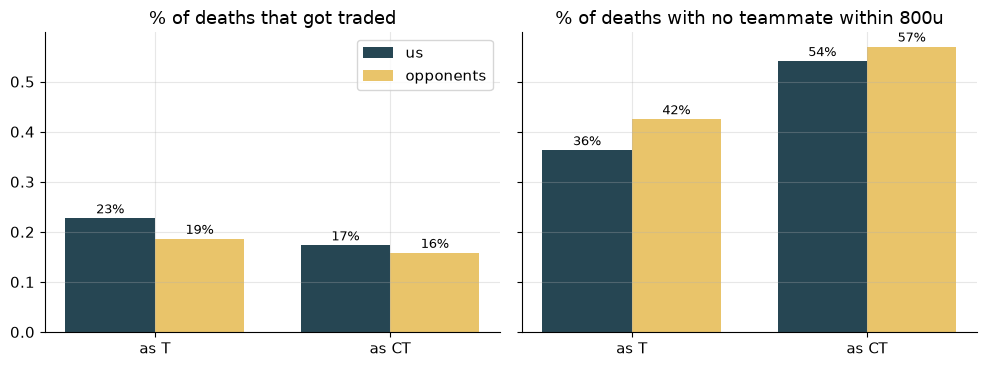

In [8]:
c = comp.reset_index()
c = c[c["death"] == "any death"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, metric, title in zip(axes, ["traded", "died_alone"], ["% of deaths that got traded", "% of deaths with no teammate within 800u"]):
    x = np.arange(2)
    for i, who in enumerate(["us", "opponents"]):
        vals = c[c["who"] == who].set_index("victim_side").loc[["T", "CT"], metric]
        ax.bar(x + (i - 0.5) * 0.38, vals, width=0.38, color=US if who == "us" else THEM, label=who)
        for xi, v in zip(x, vals):
            ax.text(xi + (i - 0.5) * 0.38, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_xticks(x, ["as T", "as CT"])
    ax.set_title(title)
axes[0].legend()
save("02_disjointed_check")

**Not really.** Compared with the people we play against, our deaths get traded *slightly more* and we die alone *slightly less*.
Everyone at this level trades badly (only ~1 in 5 deaths gets traded, for us and for them).

So "disjointed" isn't the thing that makes us different. The difference is in **who wins the first fight, and where.**

> 📝 **My take:** yes, I agree that trading deaths doesn't happen often at this rank. But when we actually decide to hit a site on T side (with everyone, or most of us), we never get enough space on the site to fight. We always get held at the entrance of whichever site we're going to, much more often at FACEIT level 8 than back at 5 or 6.

*Note for later:* that's checkable. Where do we die in rounds where 3+ of us go to the same site? The demos only cover Sep–Nov, though, so "worse than at level 5–6" can't be compared directly.

## 5. Who takes the first fight?

In [9]:
mine = pr[pr["is_my_team"]].merge(gun[["match_id", "round"]], on=["match_id", "round"])
regulars = mine["name"].value_counts()
regulars = regulars[regulars >= 150].index
who = (mine[mine["name"].isin(regulars)]
       .groupby(["name", "side"])
       .agg(rounds=("round", "size"), first_kill_rate=("opening_kills", "mean"), first_death_rate=("opening_deaths", "mean")))
who["first_duel_win_pct"] = who["first_kill_rate"] / (who["first_kill_rate"] + who["first_death_rate"])
who.round(3).unstack("side")

rounds      first_kill_rate        first_death_rate         \
side             CT    T              CT      T               CT      T   
name                                                                      
Inbail          516  493           0.163  0.116            0.110  0.108   
MlgSly          649  639           0.108  0.128            0.086  0.100   
Sad_X           418  391           0.084  0.120            0.093  0.084   
Toe_bias        600  598           0.117  0.079            0.088  0.097   
XxcanonboixX    345  340           0.064  0.071            0.070  0.118   

             first_duel_win_pct         
side                         CT      T  
name                                    
Inbail                    0.596  0.518  
MlgSly                    0.556  0.562  
Sad_X                     0.473  0.588  
Toe_bias                  0.569  0.448  
XxcanonboixX              0.478  0.375

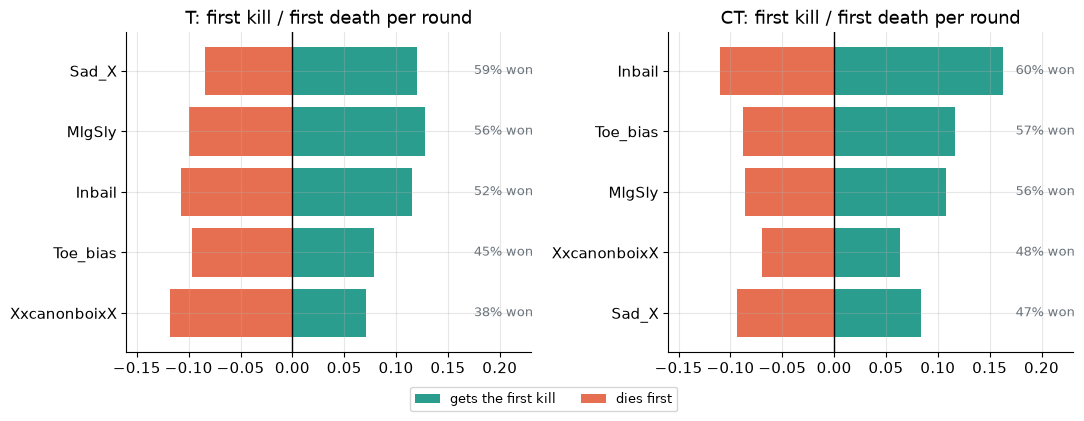

In [10]:
w = who.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, side in zip(axes, ["T", "CT"]):
    s = w[w["side"] == side].sort_values("first_duel_win_pct").reset_index(drop=True)
    y = np.arange(len(s))
    ax.barh(y, s["first_kill_rate"], color=WIN, label="gets the first kill")
    ax.barh(y, -s["first_death_rate"], color=LOSS, label="dies first")
    for yi, pct in zip(y, s["first_duel_win_pct"]):
        ax.text(0.175, yi, f"{pct:.0%} won", va="center", fontsize=9, color=NEUTRAL)
    ax.set_yticks(y, s["name"])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlim(-0.16, 0.23)
    ax.set_title(f"{side}: first kill / first death per round")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.06))
save("02_who_goes_first")

Each player's share of opening duels, per round played.
Two things to check here: who takes the most first fights, and who *wins* them.

> 📝 **My take:** cannonboi is our lurk.

*Which makes his T numbers stand out more:* a lurk usually isn't meant to be the first one to die, but XxcanonboixX dies first in 12% of T rounds and wins only 38% of those duels. Worth checking where those first deaths happen.

## 6. Where do we lose the first fight?

In [11]:
lost_open = gun[~gun["opening_ours"]]
where = (lost_open.groupby(["map", "my_side", "opening_place"])["my_team_won"]
         .agg(times="size", win_rate_after="mean").reset_index())
where["map"] = where["map"].map(MAPS)
where[where["times"] >= 8].sort_values("times", ascending=False).head(15).round(2)

,map,my_side,opening_place,times,win_rate_after
105,Mirage,T,TopofMid,43,0.21
75,Mirage,CT,BombsiteA,33,0.27
81,Mirage,CT,Middle,25,0.28
55,Inferno,CT,Banana,24,0.25
62,Inferno,T,Banana,20,0.35
100,Mirage,T,PalaceInterior,19,0.26
85,Mirage,CT,SnipersNest,17,0.29
99,Mirage,T,PalaceAlley,16,0.31
49,Dust2,T,TopofMid,16,0.44
36,Dust2,CT,MidDoors,15,0.27


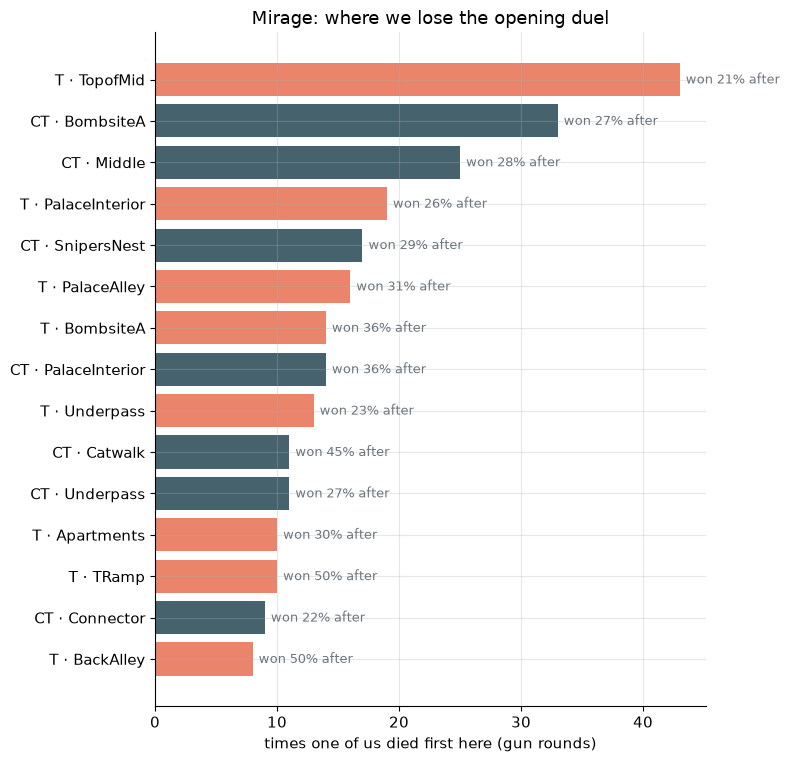

In [12]:
mir = where[(where["map"] == "Mirage") & (where["times"] >= 8)].copy()
mir["label"] = mir["my_side"] + " · " + mir["opening_place"]
mir = mir.sort_values("times")
fig, ax = plt.subplots(figsize=(8, 0.45 * len(mir) + 1))
ax.barh(mir["label"], mir["times"], color=[LOSS if s == "T" else US for s in mir["my_side"]], alpha=0.85)
for y, (n, wr) in enumerate(zip(mir["times"], mir["win_rate_after"])):
    ax.text(n + 0.5, y, f"won {wr:.0%} after", va="center", fontsize=9, color=NEUTRAL)
ax.set_xlabel("times one of us died first here (gun rounds)")
ax.set_title("Mirage: where we lose the opening duel")
save("02_mirage_first_deaths")

### Top of Mid 🎯

The #1 spot: **T side, Top of Mid**. Who dies there, and to what?

In [13]:
mk = ctx[(ctx["is_opening"]) & (ctx["victim_is_my_team"])]
mk = mk.merge(gun[["match_id", "round", "map", "my_team_won"]], on=["match_id", "round"], suffixes=("", "_r"))
top = mk[(mk["map"] == "de_mirage") & (mk["victim_side"] == "T") & (mk["victim_last_place_name"] == "TopofMid")]
print(f"{len(top)} first deaths at Top of Mid, median {top['time_s'].median():.0f}s into the round, "
      f"traded {top['traded'].mean():.0%}, round won {top['my_team_won'].mean():.0%} of the time")
pd.concat({
    "who died": top["victim_name"].value_counts().head(4),
    "killer stood at": top["attacker_last_place_name"].value_counts().head(4),
    "weapon": top["weapon"].value_counts().head(4),
}, axis=1)

43 first deaths at Top of Mid, median 11s into the round, traded 16%, round won 21% of the time


,who died,killer stood at,weapon
MlgSly,12.0,NaN,NaN
Toe_bias,12.0,NaN,NaN
Inbail,7.0,NaN,NaN
Wraith_18,2.0,NaN,NaN
SnipersNest,NaN,24.0,NaN
Middle,NaN,11.0,NaN
Catwalk,NaN,4.0,NaN
TopofMid,NaN,2.0,NaN
awp,NaN,NaN,25.0
m4a1_silencer,NaN,NaN,9.0


In [14]:
# Does smoking Window early fix it?
window = kills[kills["attacker_last_place_name"] == "SnipersNest"]
wx, wy = window["attacker_X"].median(), window["attacker_Y"].median()

mir_t = gun[(gun["map"] == "de_mirage") & (gun["my_side"] == "T")].copy()
sm = grenades[(grenades["type"] == "smoke") & grenades["thrower_is_my_team"] & (grenades["time_s"] < 25)]
sm = sm[np.hypot(sm["land_X"] - wx, sm["land_Y"] - wy) < 350]
mir_t["window_smoked"] = mir_t.set_index(["match_id", "round"]).index.isin(sm.set_index(["match_id", "round"]).index)
mir_t["died_first_topmid"] = ~mir_t["opening_ours"] & (mir_t["opening_place"] == "TopofMid")
mir_t.groupby("window_smoked").agg(rounds=("round", "size"), round_win=("my_team_won", "mean"),
                                   first_death_at_topmid=("died_first_topmid", "mean"),
                                   won_first_duel=("opening_ours", "mean")).round(3)

,rounds,round_win,first_death_at_topmid,won_first_duel
window_smoked,,,,
False,143,0.483,0.133,0.455
True,154,0.519,0.156,0.513


> 📝 **Our Mirage T plan:** we try to smoke Top of Mid most of the time, maybe 70% of the time. Toe_bias generally likes to go mid to peek with an AWP almost every round. I like to go Top of Mid to create space for the team and have more options. But generally the plan doesn't go beyond "let's go mid".

**Dead end (sort of):** smoking Window early only nudges things (round win ~48% → ~52%), and we *still* die first at Top of Mid about as often.
So it's not just "no smoke". It's more likely **timing**: peeking before the smoke blooms, or after it fades, or walking into a different angle.
The demos can't tell me what we were thinking, so the honest next step is to **watch them**:

In [15]:
# watch list: open these in CS2 (demoui) and jump to the time
watch = top[["match_id", "round", "time_s", "victim_name", "attacker_name", "attacker_last_place_name", "weapon", "traded"]]
watch.sort_values(["match_id", "round"]).head(15)

,match_id,round,time_s,victim_name,attacker_name,attacker_last_place_name,weapon,traded
82,1-008c75fe-986d-4142-9c56-da0632ca29b3,4,16.62,MlgSly,tanan29901,SnipersNest,awp,False
323,1-008c75fe-986d-4142-9c56-da0632ca29b3,11,21.38,Wraith_18,tanan29901,Middle,awp,False
595,1-008c75fe-986d-4142-9c56-da0632ca29b3,30,7.22,Wraith_18,tanan29901,SnipersNest,awp,True
147,1-016911e8-fb57-4f4f-907d-2e9429394ffd,7,9.22,0mTienThi_Am,Enheeislife,SnipersNest,awp,False
246,1-016911e8-fb57-4f4f-907d-2e9429394ffd,10,14.56,MlgSly,MP_PEET,Middle,m4a1_silencer,True
290,1-0d02b138-b277-4c29-8183-9a44c3e12e42,14,8.86,Sad_X,Cupyz1,SnipersNest,m4a1,False
436,1-2549b2a6-15b2-401d-bb24-18e3708b819c,17,8.44,Toe_bias,MooNLight742,SnipersNest,awp,False
531,1-2549b2a6-15b2-401d-bb24-18e3708b819c,21,12.09,Pen_Trix,Starz8788,SnipersNest,awp,False
573,1-2549b2a6-15b2-401d-bb24-18e3708b819c,25,7.00,Toe_bias,Starz8788,SnipersNest,awp,False
580,1-2549b2a6-15b2-401d-bb24-18e3708b819c,26,7.80,Pen_Trix,Starz8788,SnipersNest,awp,False


> 📝 **My take after watching a few:** (fill in)

## 7. Utility before the first fight

,us,opponents
as T,2.32,2.94
as CT,2.83,3.82


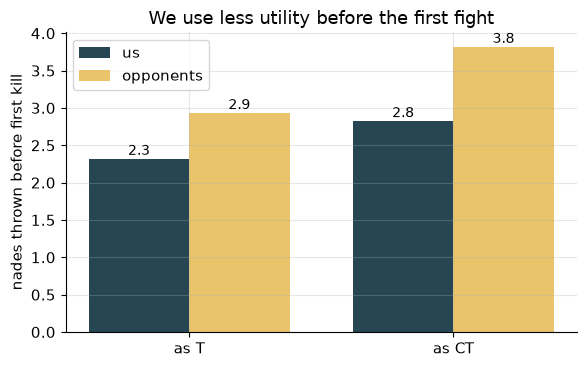

In [16]:
u = gun.groupby("my_side")[["my_util_before_contact", "enemy_util_before_contact"]].mean()
# compare like with like: our T side vs THEIR T side (= enemy util when we are CT)
like = pd.DataFrame({
    "us": [u.loc["T", "my_util_before_contact"], u.loc["CT", "my_util_before_contact"]],
    "opponents": [u.loc["CT", "enemy_util_before_contact"], u.loc["T", "enemy_util_before_contact"]],
}, index=["as T", "as CT"])
fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.arange(2)
for i, who in enumerate(["us", "opponents"]):
    ax.bar(x + (i - 0.5) * 0.38, like[who], width=0.38, color=US if who == "us" else THEM, label=who)
    for xi, v in zip(x, like[who]):
        ax.text(xi + (i - 0.5) * 0.38, v + 0.05, f"{v:.1f}", ha="center", fontsize=10)
ax.set_xticks(x, like.index)
ax.set_ylabel("nades thrown before first kill")
ax.set_title("We use less utility before the first fight")
ax.legend()
save("02_util_before_contact")
like.round(2)

On both sides we throw roughly **20–25% fewer nades before the first fight** than the teams we play against.
We save them, or use them after things have already gone wrong.

> 📝 **My take:** ok, that's interesting, I didn't know that. On CT I think most of my teammates don't understand the importance of proactive nades to gain control. To them nades are probably a reactive tool. On T side it's definitely because of lineups, I believe.

## 8. So should we play more aggressive?

My question after notebook 01: *"so should my team be playing aggressive on T and CT side?"*
Rough proxy for aggression: **how early the first fight happens.** It doesn't tell me who started it, but it does show whether rounds with early contact go better or worse.

In [17]:
g = gun.copy()
g["first_fight"] = pd.cut(g["opening_time_s"], [0, 20, 40, 60, 200], labels=["<0:20", "0:20–0:40", "0:40–1:00", "1:00+"])
timing = g.groupby(["my_side", "first_fight"], observed=True).agg(
    rounds=("round", "size"), we_won_first_duel=("opening_ours", "mean"), round_win=("my_team_won", "mean"))
timing.round(2)

rounds  we_won_first_duel  round_win
my_side first_fight                                      
CT      <0:20           492               0.54       0.51
        0:20–0:40       136               0.55       0.64
        0:40–1:00        19               0.68       0.58
        1:00+             2               0.50       0.50
T       <0:20           453               0.50       0.51
        0:20–0:40       159               0.50       0.48
        0:40–1:00        16               0.50       0.44
        1:00+            11               0.36       0.27

In [18]:
g.groupby(["my_side", "first_fight", "opening_ours"], observed=True)["my_team_won"].mean().unstack().rename(
    columns={False: "round win if we died first", True: "round win if we got first kill"}).round(2)

opening_ours         round win if we died first  \
my_side first_fight                               
CT      <0:20                              0.29   
        0:20–0:40                          0.31   
        0:40–1:00                          0.33   
        1:00+                              0.00   
T       <0:20                              0.33   
        0:20–0:40                          0.30   
        0:40–1:00                          0.25   
        1:00+                              0.14   

opening_ours         round win if we got first kill  
my_side first_fight                                  
CT      <0:20                                  0.70  
        0:20–0:40                              0.91  
        0:40–1:00                              0.69  
        1:00+                                  1.00  
T       <0:20                                  0.69  
        0:20–0:40                              0.66  
        0:40–1:00                              0.62  
        1:00+                                  0.50

**Not really "more aggressive". It's about winning the first fight, whenever it happens.**

- On both sides, most first fights happen in the first 20 seconds (71% of T rounds, 76% of CT rounds).
- When the first fight happens doesn't change much whether **we** win it (~50% on T, 54–55% on CT), and after that it's the same ~70/30 split as before.
- On CT, rounds where the first fight comes later (0:20–0:40) are actually our *best* (64% won), so holding and making T come to us is fine.
- On T, waiting doesn't help either: the few rounds with no contact until after 1:00 go badly (27%, n=11).

So aggression on its own isn't what decides it. Taking the first fight **with a teammate ready to trade, and with a nade or two**, matters more than taking it earlier.

## 9. Do we get held at the site entrance?

My gut (from section 4): *"when we actually hit a site on T side, we never get enough space on the site to fight. We always get held at the entrance."*

**How I measure a "site hit":** for each site, I group the map's callouts into the **entrance** (the last stretch the T side walks through) and the **site** itself.
A hit starts the first moment **4+ of the T team are alive in the same site's entrance or site zone** ("everyone or most of us").
Then, until the plant (or the round end), every T death is tagged as *entrance* or *site*.
I run the same thing for the **opponents when they're T against us**, so there's something to compare against.
Only Mirage, Inferno and Dust2 (55 of the 64 demos). The callout lists are my own judgement call.

In [19]:
ZONES = {  # map -> site -> (entrance callouts, site callouts)
    "de_mirage":  {"A": ({"TRamp", "PalaceInterior", "PalaceAlley"}, {"BombsiteA", "Scaffolding", "Stairs", "Jungle", "Connector", "CTSpawn"}),
                   "B": ({"Apartments", "Catwalk", "Underpass"}, {"BombsiteB", "Truck", "Shop"})},
    "de_inferno": {"A": ({"Apartments", "SecondMid", "TopofMid"}, {"BombsiteA", "Balcony", "Pit", "Quad", "Arch", "Library"}),
                   "B": ({"Banana"}, {"BombsiteB", "Ruins", "CTSpawn"})},
    "de_dust2":   {"A": ({"LongA", "LongDoors", "ShortStairs", "Catwalk"}, {"BombsiteA", "ARamp", "ExtendedA", "UnderA", "CTSpawn"}),
                   "B": ({"UpperTunnel", "LowerTunnel"}, {"BombsiteB", "BDoors", "Hole"})},
}
zone_rows = [(m, site, place, kind) for m, sites in ZONES.items() for site, (ent, on) in sites.items()
             for kind, places in (("entrance", ent), ("site", on)) for place in places]
zone_map = pd.DataFrame(zone_rows, columns=["map", "site", "place", "zone"])

rounds_g = gun[gun["map"].isin(ZONES)][["match_id", "round", "map", "my_side", "my_team_won", "bomb_planted", "plant_time_s"]]
t_alive = pos[(pos["side"] == "T") & (pos["health"] > 0)].merge(rounds_g, on=["match_id", "round"])
t_alive["team"] = np.where(t_alive["is_my_team"], "us", "them")
z = t_alive.merge(zone_map, on=["map", "place"])

# first moment 4+ of the T team are in one site's entrance/site zone
n_at = z.groupby(["match_id", "round", "team", "site", "time_s"]).size().rename("n").reset_index()
hits = (n_at[n_at["n"] >= 4].sort_values("time_s")
        .drop_duplicates(["match_id", "round", "team"]).rename(columns={"time_s": "hit_t"})
        .drop(columns="n").merge(rounds_g, on=["match_id", "round"]))
hits["t_won"] = np.where(hits["team"] == "us", hits["my_team_won"], ~hits["my_team_won"].astype(bool))

# every T death from the hit until the plant
k = kills[~kills["after_round_end"] & (kills["victim_side"] == "T")].merge(hits, on=["match_id", "round"])
k = k[(k["time_s"] >= k["hit_t"] - 3) & (~k["bomb_planted"] | (k["time_s"] <= k["plant_time_s"]))]
k = k.merge(zone_map.rename(columns={"place": "victim_last_place_name"}), on=["map", "site", "victim_last_place_name"], how="left")
k["zone"] = k["zone"].fillna("elsewhere")

ent = k[k["zone"] == "entrance"].groupby(["match_id", "round"]).size().rename("entrance_deaths")
hits = hits.join(ent, on=["match_id", "round"]).fillna({"entrance_deaths": 0})
reached = t_alive[t_alive["place"].isin(["BombsiteA", "BombsiteB"])].assign(site=lambda d: d["place"].str[-1])
reached = reached[["match_id", "round", "team", "site"]].drop_duplicates().assign(reached_site=True)
hits = hits.merge(reached, on=["match_id", "round", "team", "site"], how="left").fillna({"reached_site": False})
hits["held_at_entrance"] = hits["entrance_deaths"] >= 2   # lost 2+ before getting on

summary = hits.groupby("team").agg(
    site_hits=("round", "size"), someone_reached_site=("reached_site", "mean"), planted=("bomb_planted", "mean"),
    lost_2plus_at_entrance=("held_at_entrance", "mean"), T_round_win=("t_won", "mean"))
summary.round(2)

,site_hits,someone_reached_site,planted,lost_2plus_at_entrance,T_round_win
team,,,,,
them,242,0.880165,0.63,0.23,0.6
us,295,0.877966,0.66,0.22,0.6


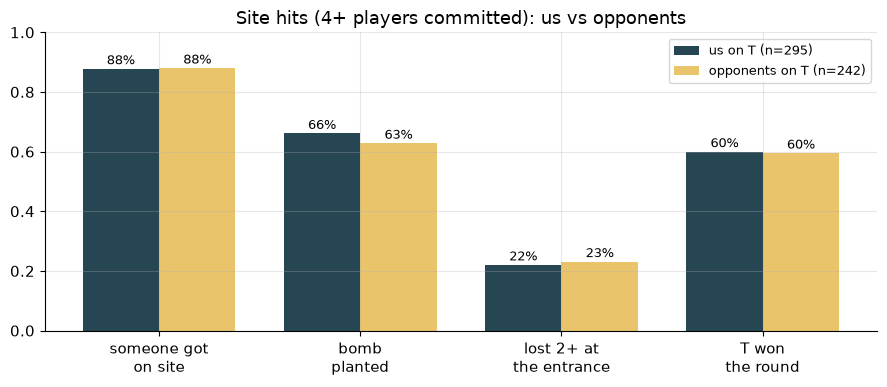

In [20]:
cols = {"someone_reached_site": "someone got\non site", "planted": "bomb\nplanted",
        "lost_2plus_at_entrance": "lost 2+ at\nthe entrance", "T_round_win": "T won\nthe round"}
x = np.arange(len(cols))
fig, ax = plt.subplots(figsize=(9, 4))
for i, who in enumerate(["us", "them"]):
    vals = summary.loc[who, list(cols)]
    ax.bar(x + (i - 0.5) * 0.38, vals, width=0.38, color=US if who == "us" else THEM,
           label=f"{'us' if who == 'us' else 'opponents'} on T (n={summary.loc[who, 'site_hits']})")
    for xi, v in zip(x, vals):
        ax.text(xi + (i - 0.5) * 0.38, v + 0.015, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, list(cols.values()))
ax.set_ylim(0, 1)
ax.set_title("Site hits (4+ players committed): us vs opponents")
ax.legend(loc="upper right", fontsize=9)
save("02_site_hits")

In [21]:
# where do T players die at the entrance, and is it traded?
e = k[k["zone"] == "entrance"].copy()
e["map"] = e["map"].map(MAPS)
spots = (e.groupby(["map", "victim_last_place_name", "team"]).size().unstack(fill_value=0)
         .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False).head(8))
display(spots)
print("entrance deaths traded:", e.groupby("team")["traded"].mean().round(2).to_dict())
print("T round win when 2+ die at the entrance:", hits[hits["held_at_entrance"]].groupby("team")["t_won"].mean().round(2).to_dict())

team                            them  us  total
map     victim_last_place_name                 
Mirage  PalaceInterior            43  48     91
        Apartments                28  28     56
Inferno Banana                    21  33     54
Dust2   LongA                     24  28     52
Mirage  TRamp                     18  18     36
Inferno Apartments                19  16     35
Mirage  PalaceAlley               10  24     34
        Catwalk                   13  12     25

entrance deaths traded: {'them': 0.23, 'us': 0.3}
T round win when 2+ die at the entrance: {'them': 0.14, 'us': 0.22}


In [22]:
# my gut said it got worse at higher level. The demos only cover level 6-7 (one match at 8).
lvl = pd.read_parquet(P / "matches.parquet")[["match_id", "my_level"]]
h = hits.merge(lvl, on="match_id")
h["level"] = h["my_level"].clip(upper=7).astype(int).map({6: "6", 7: "7+"})
h.groupby(["team", "level"]).agg(site_hits=("round", "size"), lost_2plus_at_entrance=("held_at_entrance", "mean"),
                                 planted=("bomb_planted", "mean"), T_round_win=("t_won", "mean")).round(2)

site_hits  lost_2plus_at_entrance  planted  T_round_win
team level                                                         
them 6            148                    0.23     0.59         0.58
     7+            94                    0.23     0.69         0.62
us   6            186                    0.21     0.62         0.58
     7+           109                    0.24     0.72         0.63

**Dead end: we don't get held at the entrance more than anyone else.**

- When 4+ of us commit to a site, someone gets on site **88%** of the time and we plant **66%** of the time. Our opponents on T: 88% and 63%.
- We lose 2+ players at the entrance in **22%** of hits; they do in **23%**. About a third of all T deaths during a hit happen at the entrance, for both teams.
- Getting held is brutal for everyone (T wins only 14–22% of those rounds), but it isn't a *us* problem. If anything we handle it slightly better: our entrance deaths get traded 30% of the time vs their 23%.
- Busiest entrances for both teams: **Mirage Palace**, **Inferno Banana**, **Mirage Apartments**, **Dust2 Long**.
- Level 6 vs 7: barely any change (lost 2+ at the entrance 21% → 24%, but plants and round wins went *up*). I can't test level 5–6 vs 8 because the demos don't go back that far.

So the feeling is real (getting stuck at Palace is the worst), but it happens just as often to the people we play against.
Same pattern as before: the difference shows up in the **first fight**, not in the execute.

> 📝 **My take:** I feel like even when nothing goes wrong before the hit begins, we still struggle.

### Clean hits only: nobody dead before the hit starts

Fair point, so I split the hits by what had already happened before them.

In [23]:
kk = kills[~kills["after_round_end"]].merge(hits[["match_id", "round", "hit_t"]].drop_duplicates(), on=["match_id", "round"])
before = kk[kk["time_s"] < kk["hit_t"] - 3]
dead_before = before.groupby(["match_id", "round", "victim_side"]).size().unstack(fill_value=0)
hc = hits.join(dead_before, on=["match_id", "round"]).fillna({"T": 0, "CT": 0})
hc["before_the_hit"] = np.select(
    [(hc["T"] == 0) & (hc["CT"] == 0), hc["T"] == 0],
    ["5v5, nothing happened yet", "T already up a player"], "T already lost someone")

# first kill of the hit itself: does T win it?
first = kk[kk["time_s"] >= kk["hit_t"] - 3].sort_values("time_s").drop_duplicates(["match_id", "round"])
first = first.assign(T_won_first_fight_of_hit=first["attacker_side"] == "T")[["match_id", "round", "T_won_first_fight_of_hit"]]
hc = hc.merge(first, on=["match_id", "round"], how="left")

hc.groupby(["before_the_hit", "team"]).agg(
    site_hits=("round", "size"), T_won_first_fight_of_hit=("T_won_first_fight_of_hit", "mean"),
    lost_2plus_at_entrance=("held_at_entrance", "mean"), planted=("bomb_planted", "mean"),
    T_round_win=("t_won", "mean")).round(2)

site_hits T_won_first_fight_of_hit  \
before_the_hit            team                                       
5v5, nothing happened yet them        132                 0.484848   
                          us          173                 0.491329   
T already lost someone    them         53                 0.568627   
                          us           58                 0.436364   
T already up a player     them         57                 0.571429   
                          us           64                  0.46875   

                                lost_2plus_at_entrance  planted  T_round_win  
before_the_hit            team                                                
5v5, nothing happened yet them                    0.31     0.52         0.45  
                          us                      0.26     0.58         0.49  
T already lost someone    them                    0.19     0.68         0.68  
                          us                      0.16     0.69         0.64  
T already up a player     them                    0.09     0.82         0.86  
                          us                      0.17     0.86         0.86

**You're right that clean hits are hard, but they're hard for everyone.**

- A clean 5v5 execute is basically a **coin flip**: T wins the first fight of the hit ~49% of the time and the round ~45–49%, for us *and* for opponents.
- In clean hits we actually lose 2+ at the entrance slightly *less* than opponents do (26% vs 31%), and plant slightly more (58% vs 52%).
- So the struggle is real: hitting a full, set-up CT side is just hard at this level. What turns a hit into an easy round is going in **already up a player** (86% round win for both teams), which takes us back to winning the first fight.
- One small thing to watch: when we're already up a player, we still lose 2+ at the entrance 17% of the time vs their 9%. It's a small sample (64 vs 57 hits) and doesn't cost us rounds (86% both), but it could mean we walk in a bit loose when we think we're ahead.

## Summary: answer to question 1

1. **The recurring thing in lost rounds is losing the first fight, untraded.** It happens in ~37% of gun rounds and we win only ~25% of those.
2. **We're not more disjointed than our opponents.** Trades and spacing are about the same (everyone at this level trades badly). The gut feeling probably comes from (1): when the first fight goes wrong, it *feels* like nobody's there.
3. **Mirage T, Top of Mid** is our most common first death, mostly to the Window AWP around 0:11, and a Window smoke on its own doesn't fix it.
4. **We use ~20–25% less utility before the first fight** than our opponents, on both sides.

**Things to try (the experiment later):** trade the first fight on purpose (second player right behind the entry), throw 1–2 more nades before taking the first duel, and work out a proper Top of Mid / Window routine.

> 📝 **My take, in my own words:** (3–5 bullets)